<a href="https://colab.research.google.com/github/sifatuzzaman2002/AI-Engineering-Assignments-_Machine-Learning-Part/blob/main/Module_06_Titanic_EDA_Sifatuzzaman.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Task 1: Data Loading and Initial Inspection**

In [ ]:

# Import the required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set the visual style for plots
sns.set_style("whitegrid")

# Load the Titanic dataset directly from GitHub
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/refs/heads/master/titanic.csv"
df = pd.read_csv(url)

# Display a confirmation message
print("Titanic dataset loaded successfully!")


Titanic dataset loaded successfully!


In [ ]:

# Display the first 5 rows
df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:

# Display column names, data types, and non-null counts
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:

# Generate descriptive statistics for numerical columns
df.describe()


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:

# Count missing values in each column
print("Missing values in each column:")
print(df.isnull().sum())


Missing values in each column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


# **Task 2: Handling Missing Values**

In [ ]:

# Calculate the percentage of missing values in Cabin
cabin_missing_percentage = df["Cabin"].isnull().mean() * 100

print(f"Missing Cabin values: {cabin_missing_percentage:.2f}%")


Missing Cabin values: 77.10%


In [ ]:

# Find the most frequent embarkation port
embarked_mode = df["Embarked"].mode()[0]

print("Most frequent embarkation port:", embarked_mode)

# Fill missing Embarked values with the mode
df["Embarked"] = df["Embarked"].fillna(embarked_mode)

# Verify the result
print("Missing Embarked values after imputation:",
      df["Embarked"].isnull().sum())


Most frequent embarkation port: S
Missing Embarked values after imputation: 0


In [ ]:

# Drop Cabin because most values are missing
df = df.drop(columns=["Cabin"])

# Check missing values after handling Age, Embarked, and Cabin
print("Missing values after handling:")
print(df.isnull().sum())


Missing values after handling:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Embarked         0
dtype: int64


# **Task 3: Univariate Analysis**

In [ ]:

# Calculate the percentage of passengers who survived
survival_rate = df["Survived"].mean() * 100

print(f"Overall survival rate: {survival_rate:.2f}%")


Overall survival rate: 38.38%


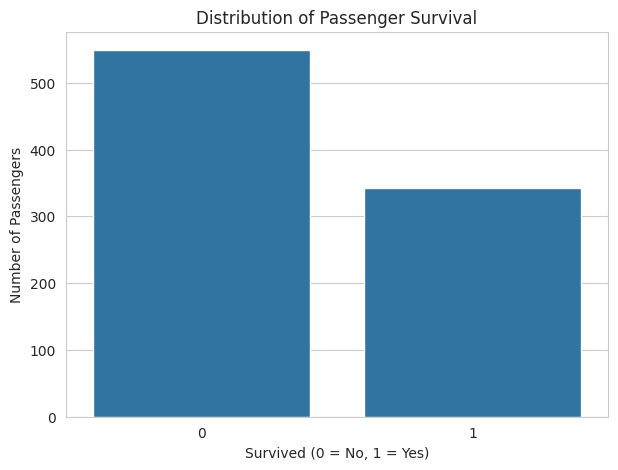

In [ ]:

# Count the number of survivors and non-survivors
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Survived")

plt.title("Distribution of Passenger Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.show()


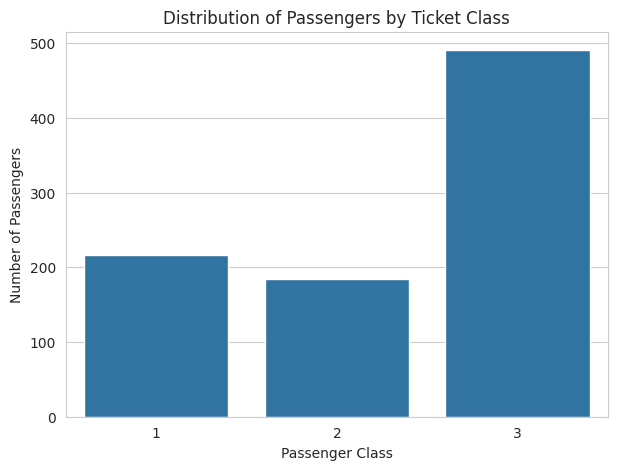

Class with the most passengers: 3


In [ ]:

# Count passengers in each ticket class
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Pclass")

plt.title("Distribution of Passengers by Ticket Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")
plt.show()

# Identify the class with the most passengers
most_common_class = df["Pclass"].mode()[0]
print("Class with the most passengers:", most_common_class)


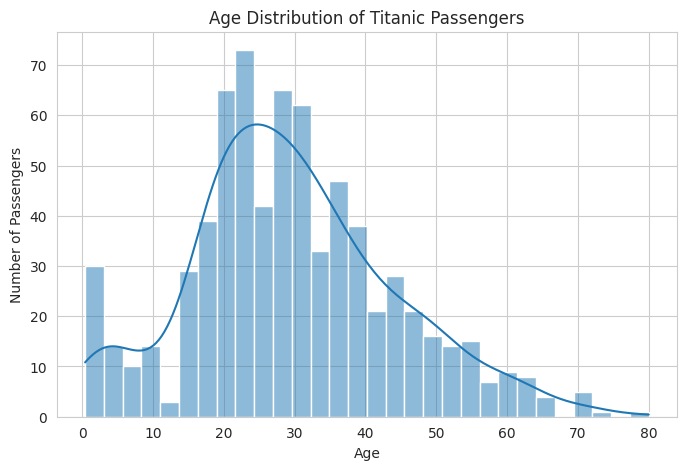

In [ ]:

# Plot a histogram of passenger ages
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Age", bins=30, kde=True)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.show()


# **Task 4: Bivariate and Multivariate Analysis**

Survival counts by sex:
Survived    0    1  All
Sex                    
female     81  233  314
male      468  109  577
All       549  342  891


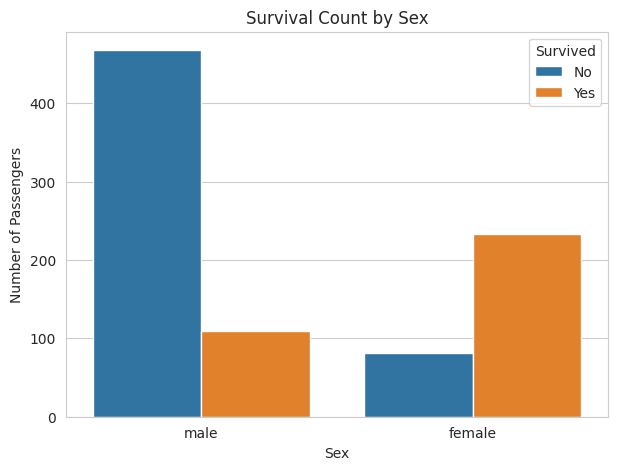


Survival rate by sex (%):
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64


In [ ]:

# Create a crosstab of survival counts by sex
sex_survival = pd.crosstab(
    df["Sex"],
    df["Survived"],
    margins=True
)

print("Survival counts by sex:")
print(sex_survival)

# Visualize survival counts by sex
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Sex", hue="Survived")

plt.title("Survival Count by Sex")
plt.xlabel("Sex")
plt.ylabel("Number of Passengers")
plt.legend(title="Survived", labels=["No", "Yes"])
plt.show()

# Calculate survival rate by sex
sex_survival_rate = df.groupby("Sex")["Survived"].mean() * 100

print("\nSurvival rate by sex (%):")
print(sex_survival_rate.round(2))


Survival rate by passenger class (%):
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


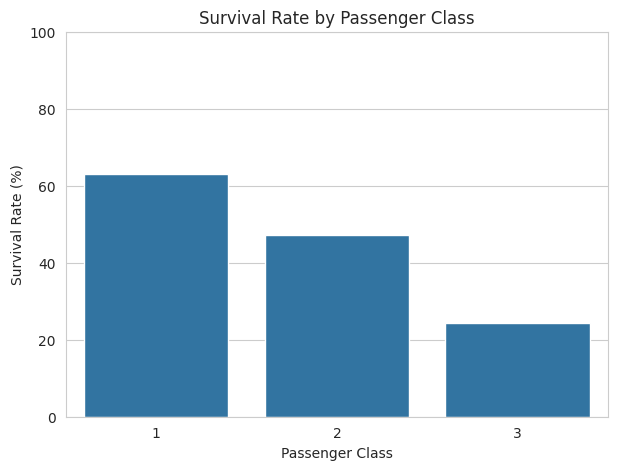

In [ ]:

# Calculate survival rate for each passenger class
class_survival_rate = (
    df.groupby("Pclass")["Survived"].mean() * 100
)

print("Survival rate by passenger class (%):")
print(class_survival_rate.round(2))

# Visualize survival rate by class
plt.figure(figsize=(7, 5))

sns.barplot(x=class_survival_rate.index,
            y=class_survival_rate.values)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)
plt.show()


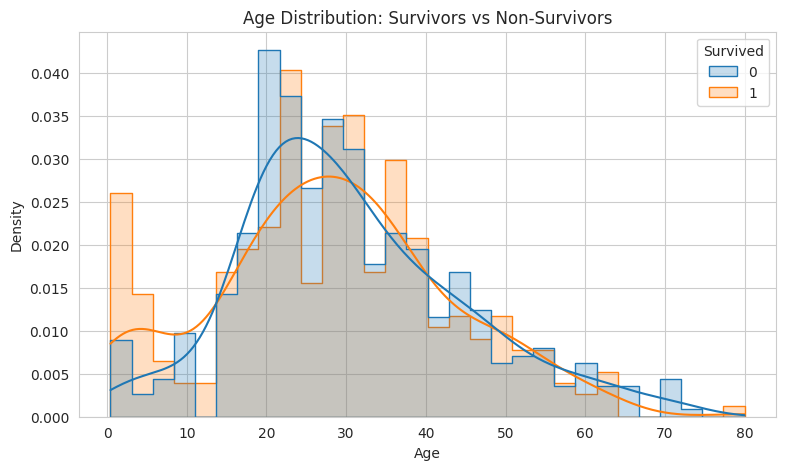

In [ ]:

# Compare age distributions for survivors and non-survivors
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Age",
    hue="Survived",
    bins=30,
    kde=True,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Age Distribution: Survivors vs Non-Survivors")
plt.xlabel("Age")
plt.ylabel("Density")
plt.show()


Survival rate by age group (%):
AgeGroup
Child          57.97
Teenager       42.86
Young Adult    38.27
Adult          40.00
Senior         22.73
Name: Survived, dtype: float64


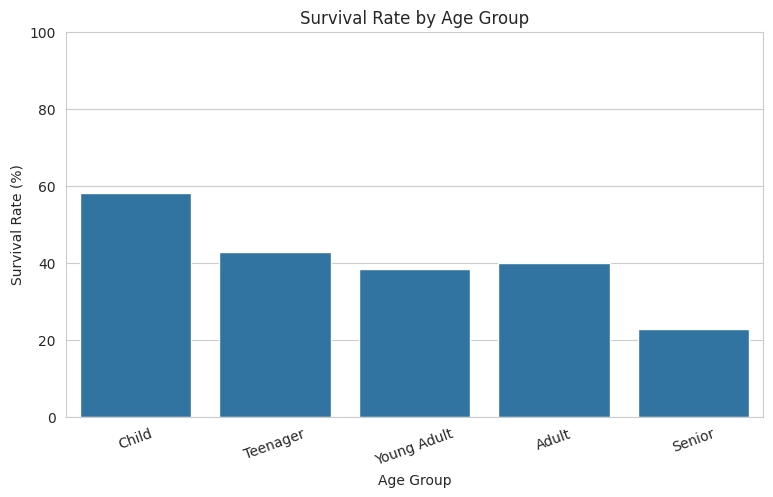

In [ ]:

# Create age groups
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teenager", "Young Adult",
            "Adult", "Senior"],
    include_lowest=True
)

# Calculate survival rate for each age group
age_group_survival = (
    df.groupby("AgeGroup", observed=False)["Survived"].mean() * 100
)

print("Survival rate by age group (%):")
print(age_group_survival.round(2))

# Visualize survival rate by age group
plt.figure(figsize=(9, 5))

sns.barplot(x=age_group_survival.index.astype(str),
            y=age_group_survival.values)

plt.title("Survival Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=20)
plt.show()


Survival rate by embarkation port (%):
Embarked
C    55.36
Q    38.96
S    33.90
Name: Survived, dtype: float64


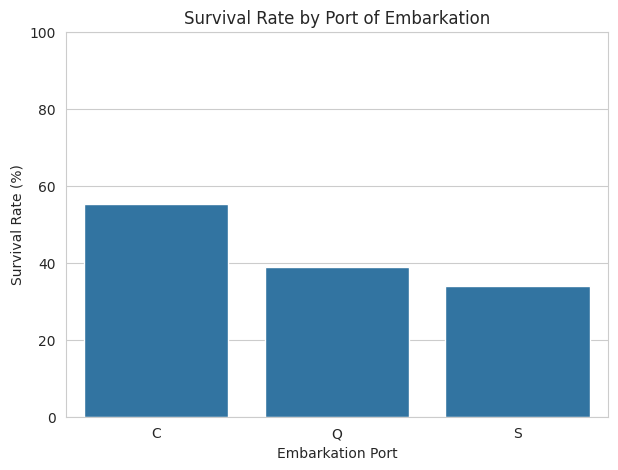

In [ ]:

# Calculate survival rate for each embarkation port
port_survival_rate = (
    df.groupby("Embarked")["Survived"].mean() * 100
)

print("Survival rate by embarkation port (%):")
print(port_survival_rate.round(2))

# Visualize survival rate by port
plt.figure(figsize=(7, 5))

sns.barplot(x=port_survival_rate.index,
            y=port_survival_rate.values)

plt.title("Survival Rate by Port of Embarkation")
plt.xlabel("Embarkation Port")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)
plt.show()


# **Task 5: Conclusion and Insights**

### Conclusion

The Exploratory Data Analysis of the Titanic dataset revealed that passenger survival was associated with several important factors. Gender was one of the strongest factors, as female passengers had a much higher survival rate than male passengers. Passenger class also played an important role, with first-class passengers having a higher survival rate than those in second and third class. Age showed some relationship with survival, while the port of embarkation also displayed differences in survival rates that may be influenced by other passenger characteristics. Overall, **Sex, Pclass, and Age** appear to be important features for understanding survival patterns in the Titanic disaster.